# 01 — Data Exploration & Visualization

Loads and documents the Jena Climate dataset — structure, missing data and the `-9999` sentinels, descriptive statistics, the temperature curve, seasonality, and sensor correlations — then presents the full **visual gallery** (trend, STL, monthly & diurnal cycles, year×month heatmap, detected anomalies, distributions, day-type clusters, correlations) on the preprocessed hourly series.

*Consolidated from the former `01_data_exploration` + `03_visualizations`.*

## 1. Dataset description

**Jena Climate (2009–2016)** — weather readings every **10 minutes**, ~420,000 rows, 14 sensor columns. Time-indexed and multi-sensor — ideal for behaviour analysis, anomaly detection, and multi-sensor reasoning.

| Column | Meaning |
| --- | --- |
| `Date Time` | timestamp (every 10 min) |
| `p (mbar)` | atmospheric pressure |
| `T (degC)` | **air temperature** (primary target) |
| `Tpot (K)` | potential temperature |
| `Tdew (degC)` | dew-point temperature |
| `rh (%)` | relative humidity |
| `VPmax/VPact/VPdef (mbar)` | vapour pressure (saturation / actual / deficit) |
| `sh (g/kg)`, `H2OC (mmol/mol)` | humidity / water-vapour concentration |
| `rho (g/m**3)` | air density |
| `wv`, `max. wv (m/s)`, `wd (deg)` | wind speed, gust, direction |

## 2. Load the data

The path is resolved by searching upward for `data/jena_climate_2009_2016.csv`, so the notebook works no matter where Jupyter was launched.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

def find_data(name="jena_climate_2009_2016.csv"):
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "data" / name
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"{name} not found; run this notebook from inside the repo.")

DATA_PATH = find_data()
print("Using:", DATA_PATH)
df = pd.read_csv(DATA_PATH)
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Using: /home/saizer/Documents/Msc_project/code/data/jena_climate_2009_2016.csv


Loaded 420,551 rows x 15 columns


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


## 3. Parse timestamps & set the time index

`Date Time` is `DD.MM.YYYY HH:MM:SS`. We convert to a datetime index so resampling, rolling stats, and decomposition all work correctly.

In [2]:
df["Date Time"] = pd.to_datetime(df["Date Time"], format="%d.%m.%Y %H:%M:%S")
df = df.set_index("Date Time").sort_index()
print("Time range:", df.index.min(), "->", df.index.max())
print("Most common interval:", df.index.to_series().diff().mode()[0])

Time range: 2009-01-01 00:10:00 -> 2017-01-01 00:00:00
Most common interval: 0 days 00:10:00


## 4. Inspect structure

In [3]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 420551 entries, 2009-01-01 00:10:00 to 2017-01-01 00:00:00
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   p (mbar)         420551 non-null  float64
 1   T (degC)         420551 non-null  float64
 2   Tpot (K)         420551 non-null  float64
 3   Tdew (degC)      420551 non-null  float64
 4   rh (%)           420551 non-null  float64
 5   VPmax (mbar)     420551 non-null  float64
 6   VPact (mbar)     420551 non-null  float64
 7   VPdef (mbar)     420551 non-null  float64
 8   sh (g/kg)        420551 non-null  float64
 9   H2OC (mmol/mol)  420551 non-null  float64
 10  rho (g/m**3)     420551 non-null  float64
 11  wv (m/s)         420551 non-null  float64
 12  max. wv (m/s)    420551 non-null  float64
 13  wd (deg)         420551 non-null  float64
dtypes: float64(14)
memory usage: 48.1 MB


## 5. Missing data & sentinel values

There are no NaNs, **but** the wind columns use `-9999` as a sentinel for a failed reading — a real data-quality issue. We detect it here; `src/preprocess.py` converts these to NaN and interpolates them.

In [4]:
print("NaNs per column:")
print(df.isna().sum()[lambda s: s > 0] if df.isna().any().any() else "None")
print("\n-9999 sentinel readings per column:")
print((df == -9999.0).sum()[lambda s: s > 0])

NaNs per column:
None

-9999 sentinel readings per column:
wv (m/s)         18
max. wv (m/s)    20
dtype: int64


## 6. Descriptive statistics (temperature focus)

In [5]:
temp = df["T (degC)"]
print(f"Temperature  min={temp.min():.2f}  max={temp.max():.2f}  "
      f"mean={temp.mean():.2f}  std={temp.std():.2f} degC")
print("Coldest at:", temp.idxmin(), "| Warmest at:", temp.idxmax())
df.describe().T

Temperature  min=-23.01  max=37.28  mean=9.45  std=8.42 degC
Coldest at: 2009-01-07 03:10:00 | Warmest at: 2015-07-04 16:00:00


,count,mean,std,min,25%,50%,75%,max
p (mbar),420551.0,989.212776,8.358481,913.60,984.20,989.58,994.72,1015.35
T (degC),420551.0,9.450147,8.423365,-23.01,3.36,9.42,15.47,37.28
Tpot (K),420551.0,283.492743,8.504471,250.60,277.43,283.47,289.53,311.34
Tdew (degC),420551.0,4.955854,6.730674,-25.01,0.24,5.22,10.07,23.11
rh (%),420551.0,76.008259,16.476175,12.95,65.21,79.30,89.40,100.00
VPmax (mbar),420551.0,13.576251,7.739020,0.95,7.78,11.82,17.60,63.77
VPact (mbar),420551.0,9.533756,4.184164,0.79,6.21,8.86,12.35,28.32
VPdef (mbar),420551.0,4.042412,4.896851,0.00,0.87,2.19,5.30,46.01
sh (g/kg),420551.0,6.022408,2.656139,0.50,3.92,5.59,7.80,18.13
H2OC (mmol/mol),420551.0,9.640223,4.235395,0.80,6.29,8.96,12.49,28.82


## 7. Temperature over time (daily mean)

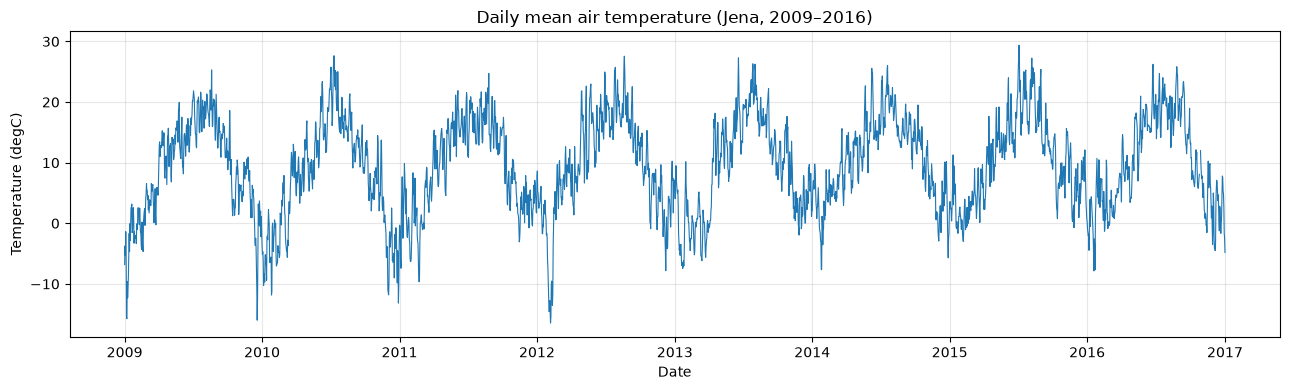

In [6]:
daily_temp = temp.resample("D").mean()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily_temp.index, daily_temp.values, linewidth=0.8)
ax.set_title("Daily mean air temperature (Jena, 2009–2016)")
ax.set_xlabel("Date"); ax.set_ylabel("Temperature (degC)"); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## Data availability & distribution shape

In [7]:
import sys
from pathlib import Path
for _b in [Path.cwd(), *Path.cwd().parents]:
    if (_b / "v1" / "src").exists():
        sys.path.insert(0, str(_b / "v1")); break
from src import analysis
# availability on the RAW frame (df still has -9999 sentinels here)
display(analysis.data_availability(df))
# distribution shape on a cleaned copy (sentinels -> NaN -> interpolated)
_clean = df.replace(-9999.0, np.nan).interpolate(limit_direction="both")
display(analysis.distribution_stats(_clean))

,n_total,n_missing,n_sentinel,n_real,available_pct
p (mbar),420551,0,0,420551,100.000000
T (degC),420551,0,0,420551,100.000000
Tpot (K),420551,0,0,420551,100.000000
Tdew (degC),420551,0,0,420551,100.000000
rh (%),420551,0,0,420551,100.000000
VPmax (mbar),420551,0,0,420551,100.000000
VPact (mbar),420551,0,0,420551,100.000000
VPdef (mbar),420551,0,0,420551,100.000000
sh (g/kg),420551,0,0,420551,100.000000
H2OC (mmol/mol),420551,0,0,420551,100.000000


,mean,median,std,skew,kurtosis,min,max
p (mbar),989.212776,989.58,8.358481,-0.407023,0.933526,913.60,1015.35
T (degC),9.450147,9.42,8.423365,-0.019272,-0.200658,-23.01,37.28
Tpot (K),283.492743,283.47,8.504471,-0.042512,-0.139672,250.60,311.34
Tdew (degC),4.955854,5.22,6.730674,-0.377110,-0.018798,-25.01,23.11
rh (%),76.008259,79.30,16.476175,-0.672158,-0.374450,12.95,100.00
VPmax (mbar),13.576251,11.82,7.739020,1.311042,2.397063,0.95,63.77
VPact (mbar),9.533756,8.86,4.184164,0.556607,-0.249778,0.79,28.32
VPdef (mbar),4.042412,2.19,4.896851,2.365400,7.359157,0.00,46.01
sh (g/kg),6.022408,5.59,2.656139,0.567905,-0.223676,0.50,18.13
H2OC (mmol/mol),9.640223,8.96,4.235395,0.560890,-0.235907,0.80,28.82


## 8. Multi-sensor relationships

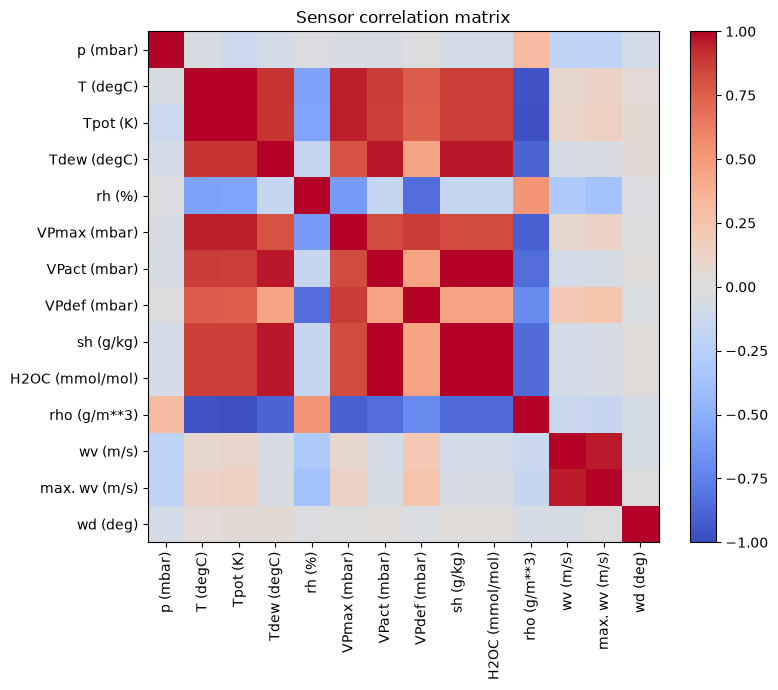

Strongest correlations with temperature:
Tpot (K)           0.996827
VPmax (mbar)       0.951113
Tdew (degC)        0.895708
VPact (mbar)       0.867673
H2OC (mmol/mol)    0.867177
sh (g/kg)          0.866755
VPdef (mbar)       0.761744
max. wv (m/s)      0.125164
wv (m/s)           0.088666
wd (deg)           0.038732
p (mbar)          -0.045375
rh (%)            -0.572416
rho (g/m**3)      -0.963410
Name: T (degC), dtype: float64


In [8]:
# replace the -9999 sentinels before correlating so wind isn't distorted
clean = df.replace(-9999.0, np.nan).interpolate(limit_direction="both")
corr = clean.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns))); ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); ax.set_title("Sensor correlation matrix")
plt.tight_layout(); plt.show()
print("Strongest correlations with temperature:")
print(corr["T (degC)"].drop("T (degC)").sort_values(ascending=False))

---
## Part 2 — Visual gallery (preprocessed hourly series)

The plots below use the cleaned, hourly-aligned series from `src/preprocess.py`.

In [9]:
# setup: imports + load + preprocess (self-healing path)
import sys, importlib.util
from pathlib import Path
if importlib.util.find_spec("pandas") is None:
    _tag = f"python{sys.version_info.major}.{sys.version_info.minor}"
    for _b in [Path.cwd(), *Path.cwd().parents]:
        _sp = _b / ".venv" / "lib" / _tag / "site-packages"
        if _sp.exists():
            sys.path.insert(0, str(_sp)); break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_repo():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "jena_climate_2009_2016.csv").exists():
            return base
    raise FileNotFoundError("Run from inside the repo.")

ROOT = find_repo()
sys.path.insert(0, str(ROOT))
from src import preprocess, analysis, anomaly, clustering

df = preprocess.align(preprocess.clean(preprocess.load_data(ROOT / "data" / "jena_climate_2009_2016.csv")), freq="1h")
SENSOR = "T (degC)"
temp = df[SENSOR]
print(f"Ready: {df.shape[0]:,} hourly rows, {df.shape[1]} sensors.")

Ready: 70,129 hourly rows, 14 sensors.


## 1. Whole series + 30-day rolling mean
*Takeaway: the long-term trend under the noisy hourly signal.*

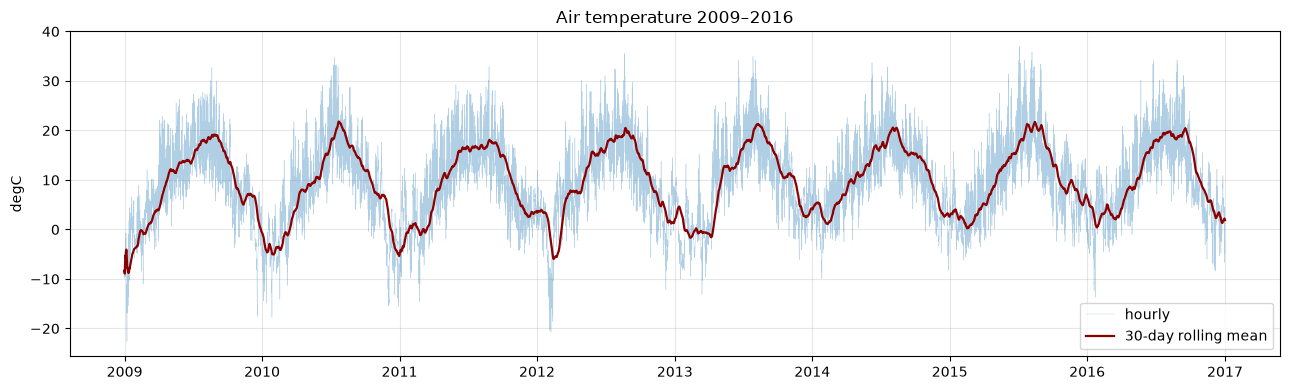

In [10]:
roll = temp.rolling(24 * 30, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(temp.index, temp.values, lw=0.3, alpha=0.35, label="hourly")
ax.plot(roll.index, roll.values, color="darkred", lw=1.6, label="30-day rolling mean")
ax.set_title("Air temperature 2009–2016"); ax.set_ylabel("degC"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2. STL decomposition (2014)
*Takeaway: the signal splits into trend + a clean daily seasonal cycle + residual (where anomalies live).*

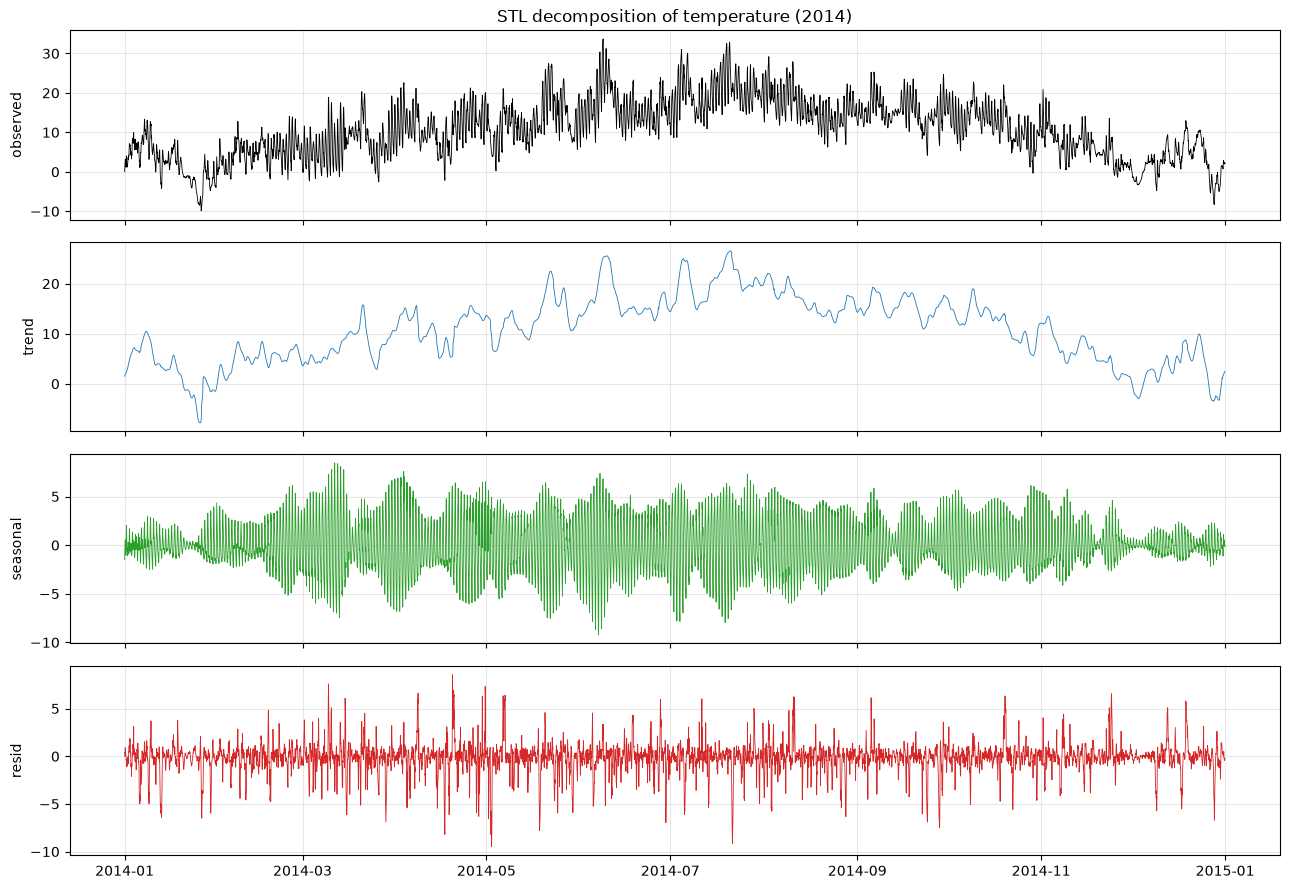

In [11]:
dec = analysis.decompose(temp.loc["2014"], period=24)
fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
for ax, (col, c) in zip(axes, [("observed", "k"), ("trend", "tab:blue"), ("seasonal", "tab:green"), ("resid", "tab:red")]):
    ax.plot(dec.index, dec[col], color=c, lw=0.6); ax.set_ylabel(col); ax.grid(alpha=0.3)
axes[0].set_title("STL decomposition of temperature (2014)")
plt.tight_layout(); plt.show()

## 3. Monthly distribution (seasonality)
*Takeaway: clear seasonal shape — cold winters, warm summers, wide spread in transition months.*

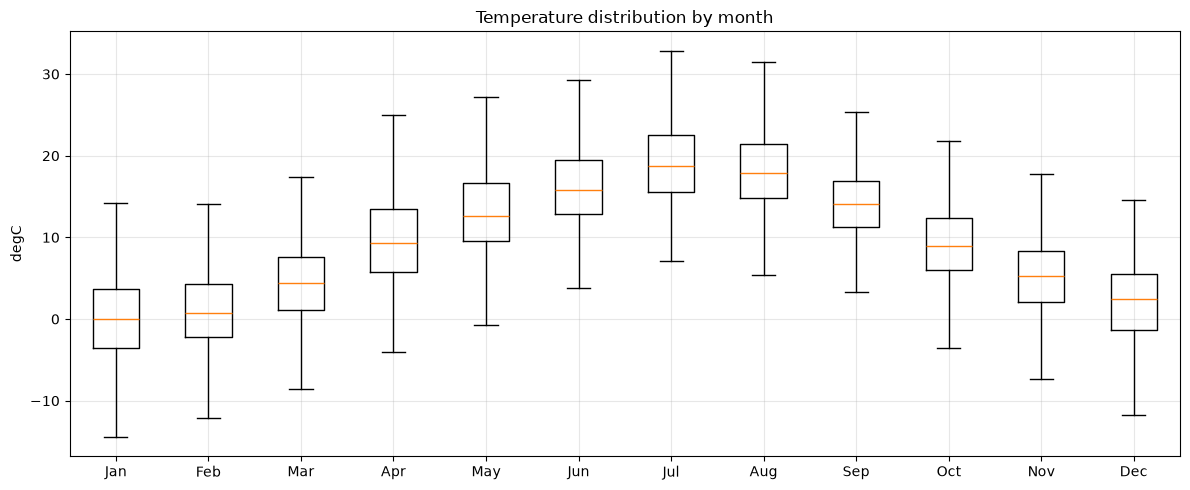

In [12]:
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
by_month = [temp[temp.index.month == m].values for m in range(1, 13)]
fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(by_month, showfliers=False)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(months)
ax.set_title("Temperature distribution by month"); ax.set_ylabel("degC"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Daily (diurnal) cycle
*Takeaway: average temperature by hour — coldest before dawn, peak mid-afternoon.*

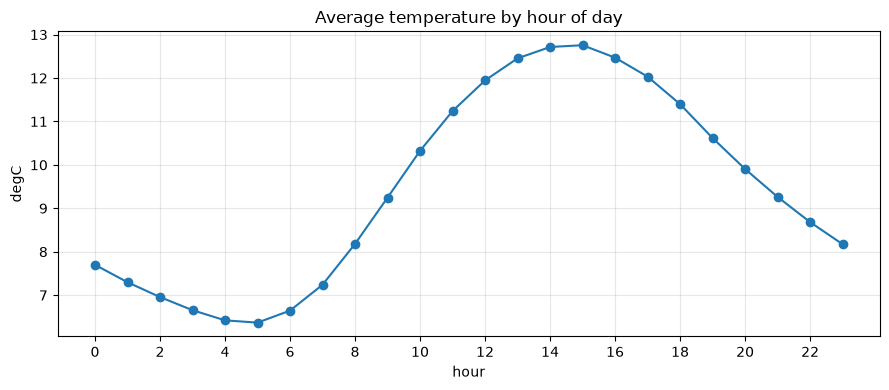

In [13]:
hourly = temp.groupby(temp.index.hour).mean()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hourly.index, hourly.values, marker="o")
ax.set_title("Average temperature by hour of day"); ax.set_xlabel("hour"); ax.set_ylabel("degC")
ax.set_xticks(range(0, 24, 2)); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Year × month heatmap of mean temperature
*Takeaway: see warm/cold months across years at a glance (e.g. hot summer 2015).*

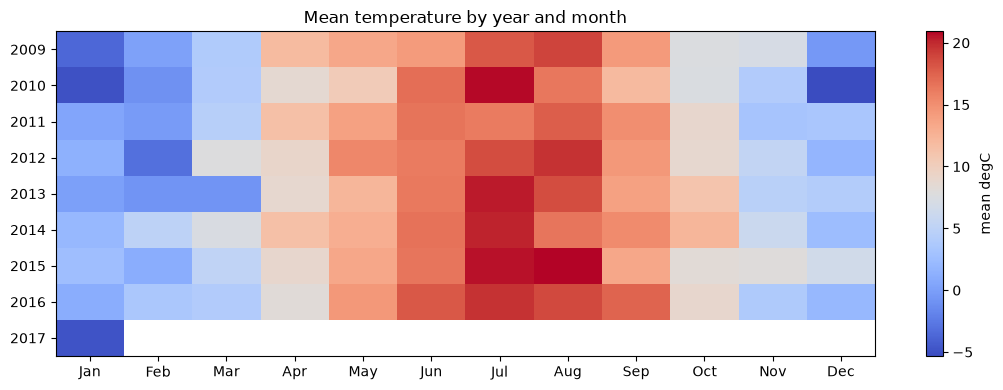

In [14]:
pivot = temp.groupby([temp.index.year, temp.index.month]).mean().unstack()
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(pivot.values, aspect="auto", cmap="coolwarm")
ax.set_xticks(range(12)); ax.set_xticklabels(months)
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index)
fig.colorbar(im, ax=ax, label="mean degC"); ax.set_title("Mean temperature by year and month")
plt.tight_layout(); plt.show()

## 6. Detected anomalies on the full series
*Takeaway: where the residual z-score flags unusual readings across all 8 years.*

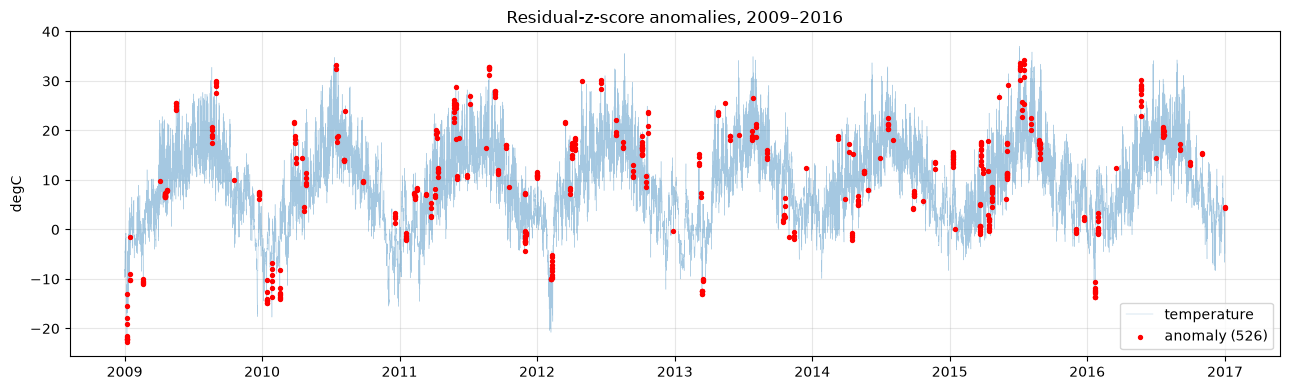

In [15]:
dec_full = analysis.decompose(temp, period=24)
ra = anomaly.zscore_anomalies(dec_full["resid"].dropna(), threshold=4.0)
flagged = ra[ra].index
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(temp.index, temp.values, lw=0.3, alpha=0.4, label="temperature")
ax.scatter(flagged, temp.loc[flagged], color="red", s=8, zorder=3, label=f"anomaly ({len(flagged)})")
ax.set_title("Residual-z-score anomalies, 2009–2016"); ax.set_ylabel("degC"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Distributions: temperature vs residual
*Takeaway: raw temperature is broad/seasonal; the residual is tight and centred on 0, so large residuals stand out as anomalies.*

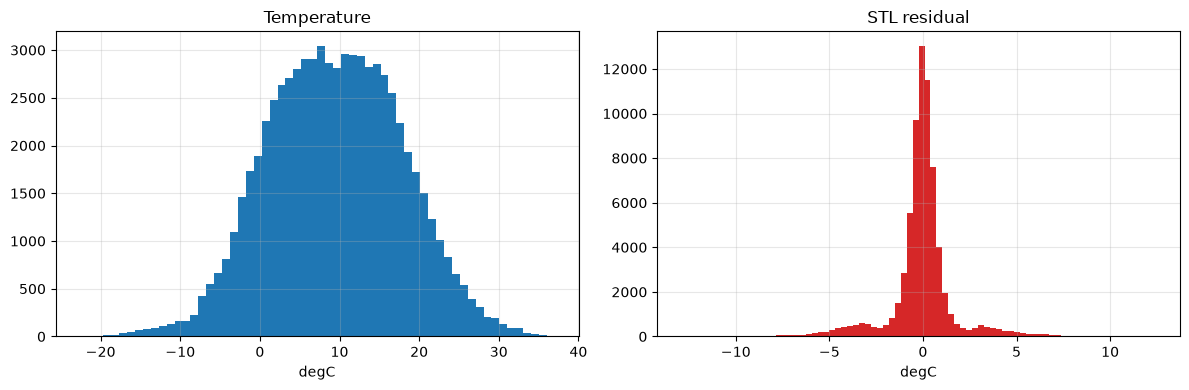

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(temp.values, bins=60, color="tab:blue"); axes[0].set_title("Temperature"); axes[0].set_xlabel("degC")
axes[1].hist(dec_full["resid"].dropna().values, bins=80, color="tab:red"); axes[1].set_title("STL residual"); axes[1].set_xlabel("degC")
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 8. Clusters: temperature vs humidity (day-types)
*Takeaway: K-means day-types separate cleanly into cold/humid → warm/dry groups.*

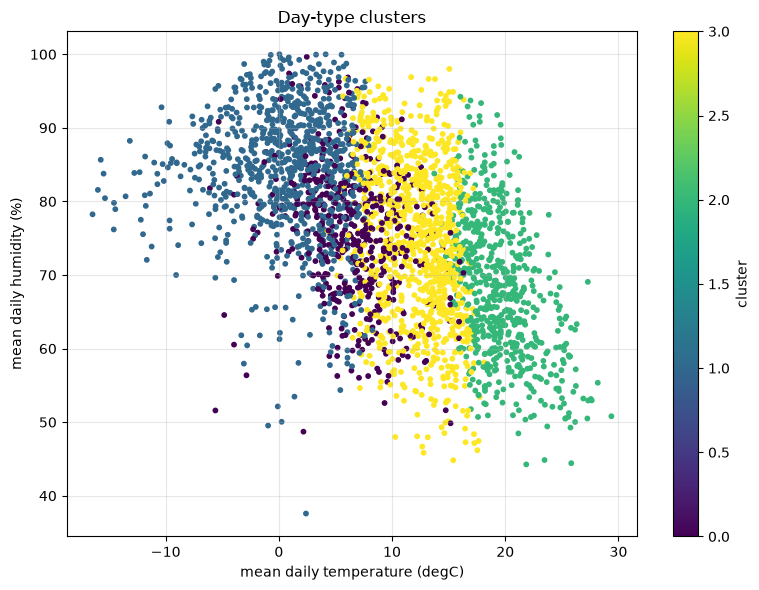

In [17]:
feats = clustering.daily_features(df)
labels = clustering.kmeans_cluster(feats, k=4)
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(feats["mean_T (degC)"], feats["mean_rh (%)"], c=labels.values, cmap="viridis", s=10)
ax.set_xlabel("mean daily temperature (degC)"); ax.set_ylabel("mean daily humidity (%)")
ax.set_title("Day-type clusters"); fig.colorbar(sc, ax=ax, label="cluster"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 9. What correlates with temperature
*Takeaway: density moves opposite to temperature; potential temp and vapour pressure move with it.*

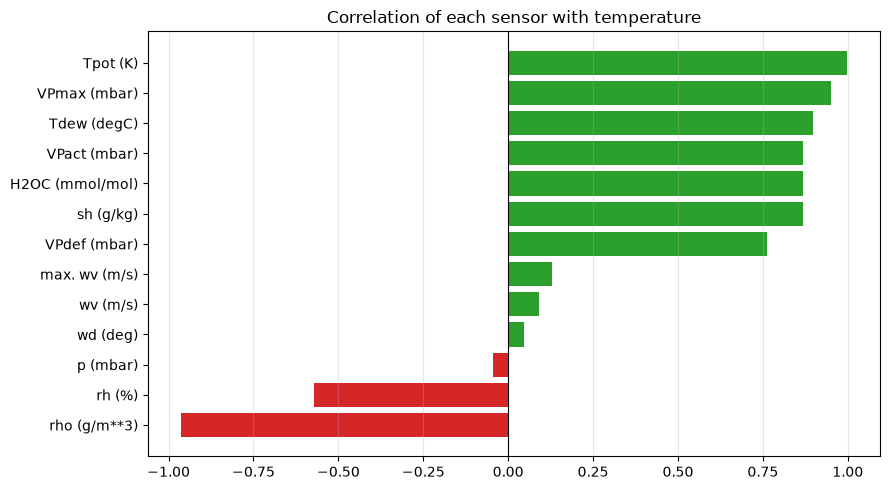

In [18]:
corr_t = df.corr(numeric_only=True)[SENSOR].drop(SENSOR).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["tab:red" if v < 0 else "tab:green" for v in corr_t.values]
ax.barh(corr_t.index, corr_t.values, color=colors)
ax.axvline(0, color="k", lw=0.8); ax.set_title("Correlation of each sensor with temperature"); ax.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()

---
## Next steps
- **Methods & correctness:** `02_methods_and_evaluation.ipynb` — query engine, anomaly detection, clustering, and verification vs pandas ground truth.
- **Interface:** `03_interface_reasoning.ipynb` — ask questions in natural language.